In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set visual style
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

# Load dataset dengan melewati baris bermasalah jika ada
df_raw = pd.read_csv('indonesia_mbg_nationwide_enriched_2026.csv', on_bad_lines='skip')

# Definisi fitur dan target fokus
target = 'primary_food_waste_driver'
features = [
    'beneficiary_category',
    'protein_type',
    'food_arrival_temperature_celsius',
    'transit_time_minutes',
    'plate_waste_percentage'
]

# Subsetting dataframe
df = df_raw[features + [target]].copy()

print("--- INFORMASI SUBSET DATASET FOKUS ---")
df.info()
print("\n--- SANITY CHECK (MISSING VALUES) ---")
print(df.isnull().sum())
df.head()

--- INFORMASI SUBSET DATASET FOKUS ---
<class 'pandas.DataFrame'>
RangeIndex: 13000 entries, 0 to 12999
Data columns (total 6 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   beneficiary_category              13000 non-null  str    
 1   protein_type                      13000 non-null  str    
 2   food_arrival_temperature_celsius  13000 non-null  float64
 3   transit_time_minutes              13000 non-null  int64  
 4   plate_waste_percentage            13000 non-null  float64
 5   primary_food_waste_driver         13000 non-null  str    
dtypes: float64(2), int64(1), str(3)
memory usage: 609.5 KB

--- SANITY CHECK (MISSING VALUES) ---
beneficiary_category                0
protein_type                        0
food_arrival_temperature_celsius    0
transit_time_minutes                0
plate_waste_percentage              0
primary_food_waste_driver           0
dtype: int64


,beneficiary_category,protein_type,food_arrival_temperature_celsius,transit_time_minutes,plate_waste_percentage,primary_food_waste_driver
0,Balita & Ibu Hamil Posyandu,Daging Sapi / Kerbau,56.9,77,16.3,Delivery-Transit-Delay
1,Siswa SD / Madrasah Ibtidaiyah,Daging Ayam Broiler,65.5,18,13.8,Prior-Snack-Consumption
2,Siswa SD / Madrasah Ibtidaiyah,Daging Ayam Broiler,68.0,12,14.9,Prior-Snack-Consumption
3,Siswa SMA / SMK / MA,Daging Ayam Broiler,64.4,23,9.8,Prior-Snack-Consumption
4,Siswa SD / Madrasah Ibtidaiyah,Daging Ayam Broiler,58.8,21,13.8,Prior-Snack-Consumption


Memeriksa keseimbangan jumlah sampel di setiap kelas target.

=== DISTRIBUSI KELAS TARGET ===
                                 Jumlah  Persentase (%)
primary_food_waste_driver                              
Prior-Snack-Consumption            8246           63.43
Excessive-Portion-Size             2912           22.40
Sub-Optimal-Arrival-Temperature    1115            8.58
Delivery-Transit-Delay              525            4.04
Low-Palatability-Menu               202            1.55


C:\Users\anoma\AppData\Local\Temp\ipykernel_17988\1351447591.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(x=target_counts.index, y=target_counts.values, palette='Blues_r')


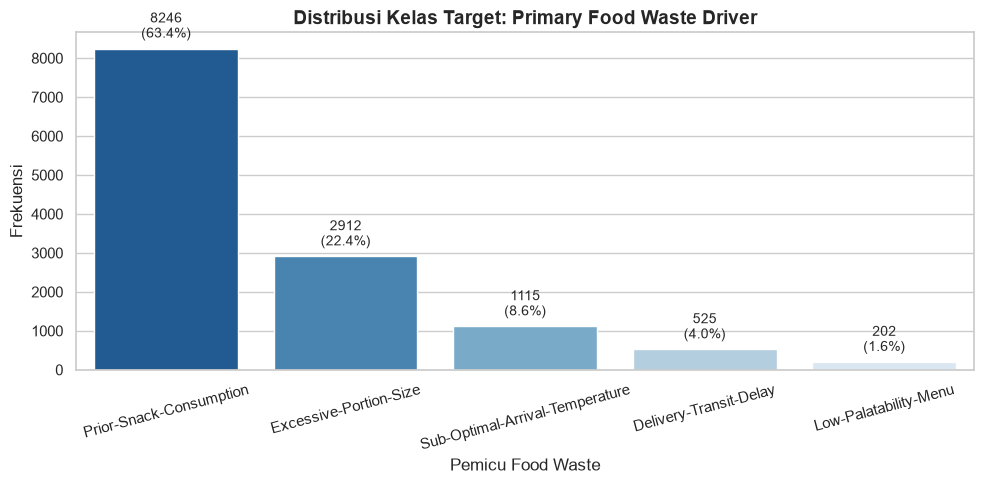

In [2]:
# Hitung frekuensi & persentase
target_counts = df[target].value_counts()
target_pct = df[target].value_counts(normalize=True) * 100

df_target = pd.DataFrame({'Jumlah': target_counts, 'Persentase (%)': target_pct.round(2)})
print("=== DISTRIBUSI KELAS TARGET ===")
print(df_target)

# Visualisasi Bar Chart
plt.figure(figsize=(10, 5))
ax = sns.barplot(x=target_counts.index, y=target_counts.values, palette='Blues_r')
plt.title('Distribusi Kelas Target: Primary Food Waste Driver', fontsize=14, fontweight='bold')
plt.xlabel('Pemicu Food Waste')
plt.ylabel('Frekuensi')
plt.xticks(rotation=15)

for p in ax.patches:
    ax.annotate(f'{int(p.get_height())}\n({p.get_height()/len(df)*100:.1f}%)',
                (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='bottom', fontsize=10, xytext=(0, 5), textcoords='offset points')

plt.tight_layout()
plt.show()

Melihat statistik deskriptif dan histogram sebaran nilai untuk 3 variabel angka.

=== STATISTIK DESKRIPTIF FITUR NUMERIK ===
                                   mean    std   min   50%    max
food_arrival_temperature_celsius  62.88   8.12  30.0  65.7   72.0
transit_time_minutes              24.67  21.39   5.0  18.0  120.0
plate_waste_percentage            13.34   5.58   1.0  13.2   37.7


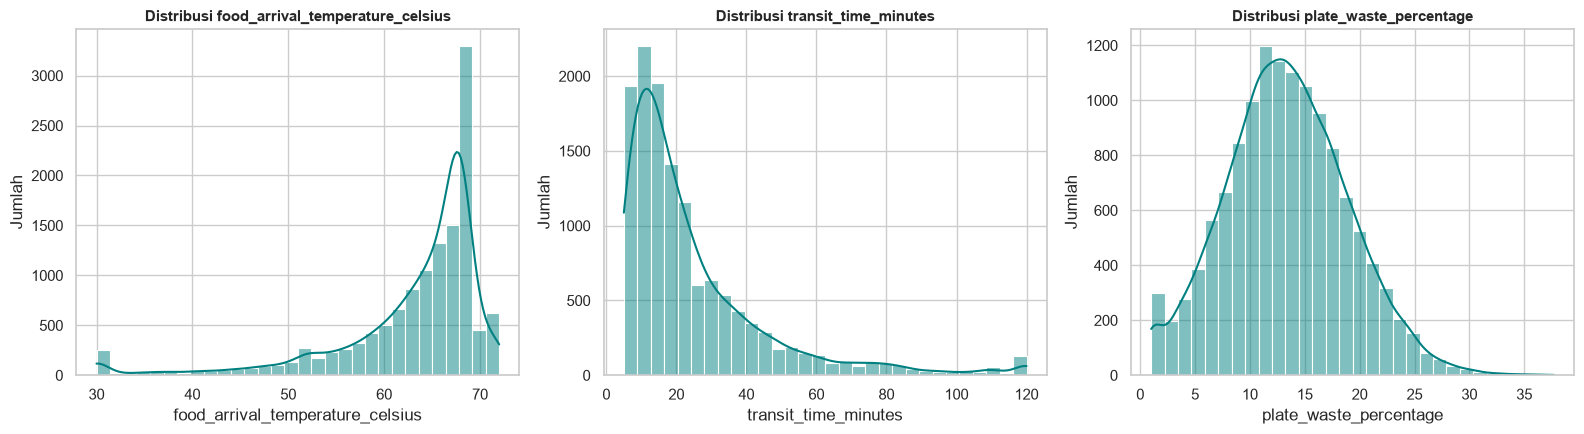

In [3]:
num_cols = ['food_arrival_temperature_celsius', 'transit_time_minutes', 'plate_waste_percentage']

print("=== STATISTIK DESKRIPTIF FITUR NUMERIK ===")
print(df[num_cols].describe().T[['mean', 'std', 'min', '50%', 'max']].round(2))

# Visualisasi Histogram & KDE
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

for i, col in enumerate(num_cols):
    sns.histplot(df[col], kde=True, ax=axes[i], color='teal', bins=30)
    axes[i].set_title(f'Distribusi {col}', fontsize=11, fontweight='bold')
    axes[i].set_ylabel('Jumlah')

plt.tight_layout()
plt.show()

Memeriksa sebaran frekuensi untuk masing-masing kategori sasaran penerima dan jenis protein.

C:\Users\anoma\AppData\Local\Temp\ipykernel_17988\1651778647.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(y=counts.index, x=counts.values, ax=axes[i], palette='Set2')
C:\Users\anoma\AppData\Local\Temp\ipykernel_17988\1651778647.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(y=counts.index, x=counts.values, ax=axes[i], palette='Set2')


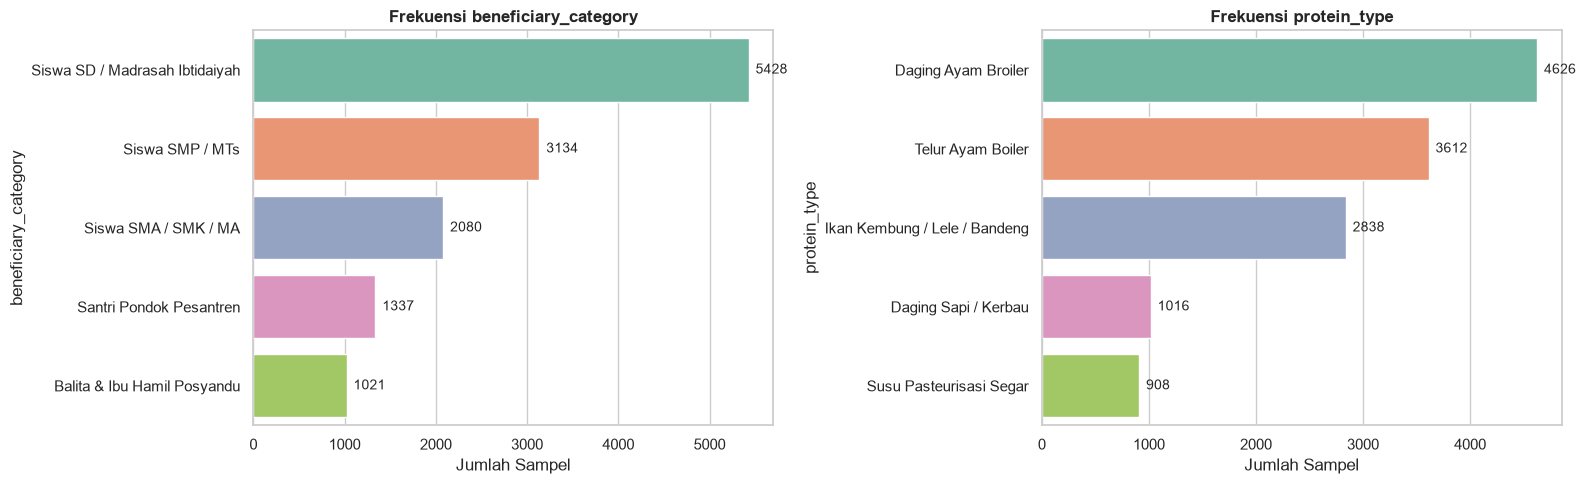

In [4]:
cat_cols = ['beneficiary_category', 'protein_type']

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

for i, col in enumerate(cat_cols):
    counts = df[col].value_counts()
    sns.barplot(y=counts.index, x=counts.values, ax=axes[i], palette='Set2')
    axes[i].set_title(f'Frekuensi {col}', fontsize=12, fontweight='bold')
    axes[i].set_xlabel('Jumlah Sampel')

    for p in axes[i].patches:
        width = p.get_width()
        axes[i].annotate(f'{int(width)}', (width, p.get_y() + p.get_height() / 2.),
                         ha='left', va='center', fontsize=10, xytext=(5, 0), textcoords='offset points')

plt.tight_layout()
plt.show()

Memeriksa bagaimana rata-rata dan sebaran nilai Suhu, Waktu Transit, dan Sisa Makanan berbeda di setiap kelas pemicu Food Waste.

=== RATA-RATA FITUR NUMERIK BERDASARKAN PEMICU FOOD WASTE ===
                                 food_arrival_temperature_celsius  \
primary_food_waste_driver                                           
Delivery-Transit-Delay                                      55.92   
Excessive-Portion-Size                                      65.08   
Low-Palatability-Menu                                       64.44   
Prior-Snack-Consumption                                     65.38   
Sub-Optimal-Arrival-Temperature                             41.68   

                                 transit_time_minutes  plate_waste_percentage  
primary_food_waste_driver                                                      
Delivery-Transit-Delay                          69.47                   12.96  
Excessive-Portion-Size                          17.85                   18.97  
Low-Palatability-Menu                           18.76                   20.35  
Prior-Snack-Consumption                         18.22 

C:\Users\anoma\AppData\Local\Temp\ipykernel_17988\933116965.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x=target, y='food_arrival_temperature_celsius', ax=axes[0], palette='Reds')
C:\Users\anoma\AppData\Local\Temp\ipykernel_17988\933116965.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x=target, y='transit_time_minutes', ax=axes[1], palette='Purples')


C:\Users\anoma\AppData\Local\Temp\ipykernel_17988\933116965.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x=target, y='plate_waste_percentage', ax=axes[2], palette='Oranges')


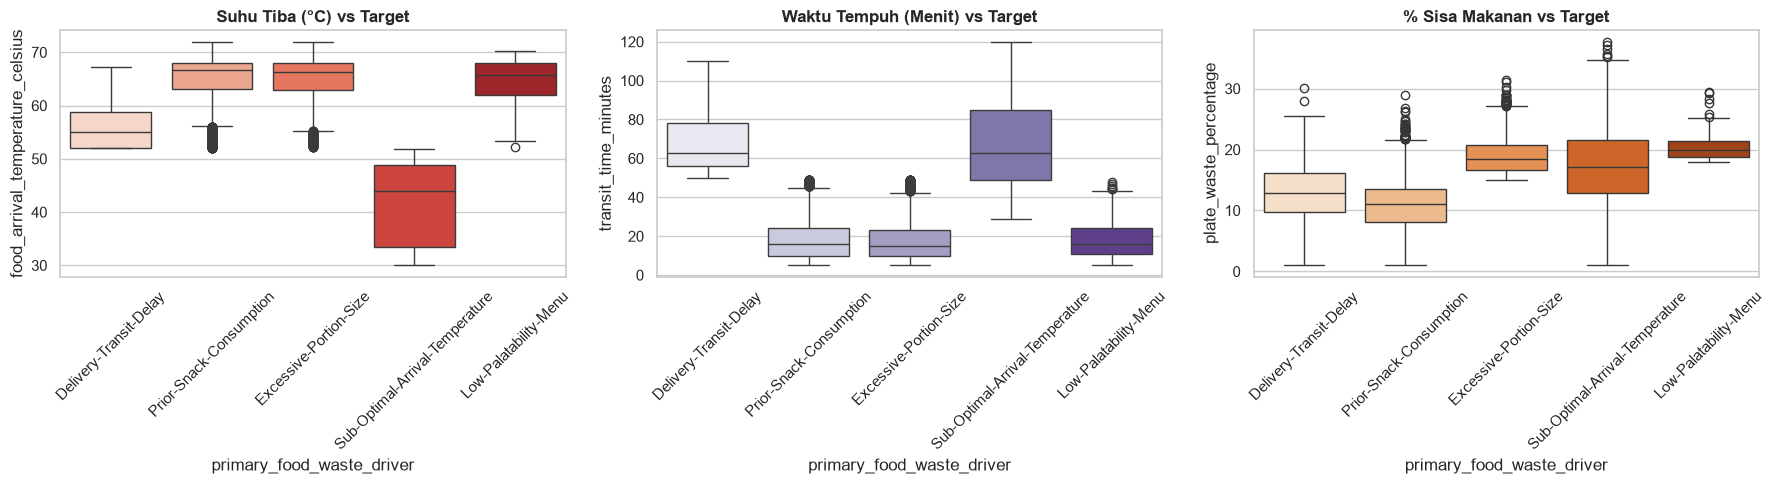

In [5]:
# Groupby mean
mean_by_target = df.groupby(target)[num_cols].mean().round(2)
print("=== RATA-RATA FITUR NUMERIK BERDASARKAN PEMICU FOOD WASTE ===")
print(mean_by_target)

# Boxplot visualisasi pemisahan fitur numerik
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.boxplot(data=df, x=target, y='food_arrival_temperature_celsius', ax=axes[0], palette='Reds')
axes[0].set_title('Suhu Tiba (°C) vs Target', fontweight='bold')
axes[0].tick_params(axis='x', rotation=45)

sns.boxplot(data=df, x=target, y='transit_time_minutes', ax=axes[1], palette='Purples')
axes[1].set_title('Waktu Tempuh (Menit) vs Target', fontweight='bold')
axes[1].tick_params(axis='x', rotation=45)

sns.boxplot(data=df, x=target, y='plate_waste_percentage', ax=axes[2], palette='Oranges')
axes[2].set_title('% Sisa Makanan vs Target', fontweight='bold')
axes[2].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

Melihat keterkaitan antara Kategori Penerima dan Jenis Protein terhadap jenis pemicu food waste menggunakan Cross-Tabulation dan Heatmap.

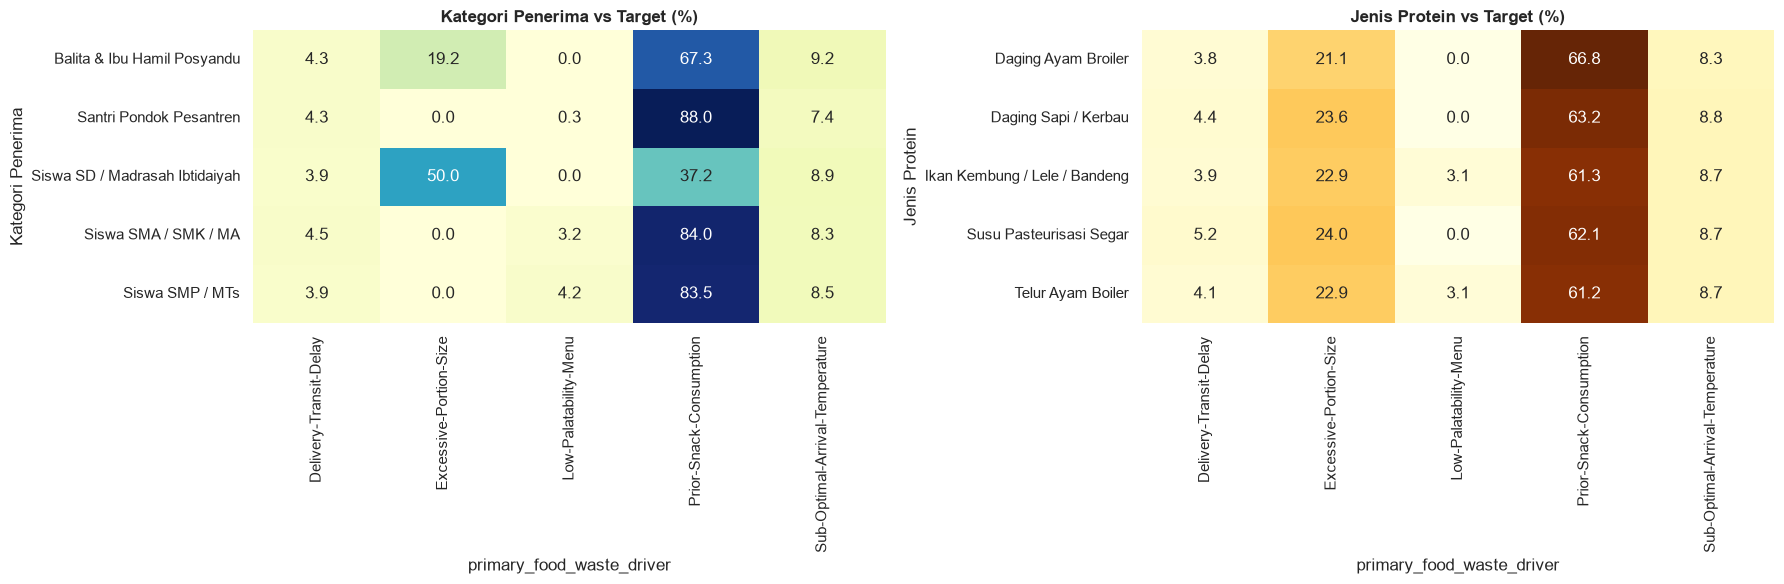

In [6]:
# Crosstab 1: Beneficiary Category vs Target (%)
ct_beneficiary = pd.crosstab(df['beneficiary_category'], df[target], normalize='index') * 100

# Crosstab 2: Protein Type vs Target (%)
ct_protein = pd.crosstab(df['protein_type'], df[target], normalize='index') * 100

fig, axes = plt.subplots(1, 2, figsize=(18, 6))

sns.heatmap(ct_beneficiary, annot=True, fmt=".1f", cmap="YlGnBu", ax=axes[0], cbar=False)
axes[0].set_title('Kategori Penerima vs Target (%)', fontweight='bold')
axes[0].set_ylabel('Kategori Penerima')

sns.heatmap(ct_protein, annot=True, fmt=".1f", cmap="YlOrBr", ax=axes[1], cbar=False)
axes[1].set_title('Jenis Protein vs Target (%)', fontweight='bold')
axes[1].set_ylabel('Jenis Protein')

plt.tight_layout()
plt.show()

Memeriksa apakah ada hubungan erat linier antara waktu transit, suhu tiba, dan persentase sisa piring (mengecek potensi redundansi).

=== MATRIKS KORELASI NUMERIK ===
                                  food_arrival_temperature_celsius  \
food_arrival_temperature_celsius                             1.000   
transit_time_minutes                                        -0.863   
plate_waste_percentage                                      -0.252   

                                  transit_time_minutes  plate_waste_percentage  
food_arrival_temperature_celsius                -0.863                  -0.252  
transit_time_minutes                             1.000                   0.198  
plate_waste_percentage                           0.198                   1.000  


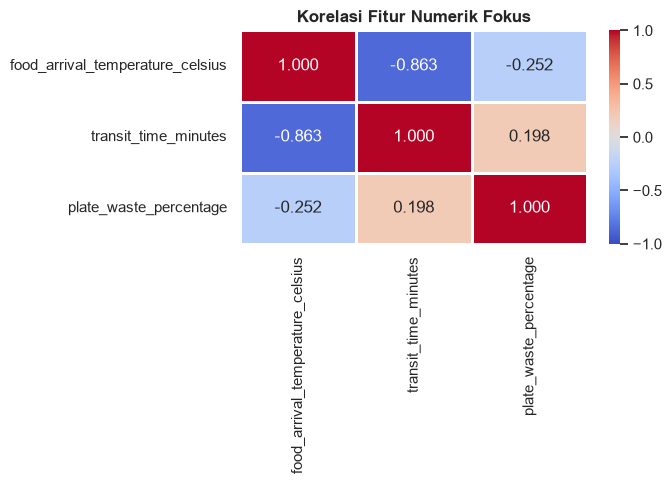

In [7]:
corr_matrix = df[num_cols].corr().round(3)

print("=== MATRIKS KORELASI NUMERIK ===")
print(corr_matrix)

plt.figure(figsize=(7, 5))
sns.heatmap(corr_matrix, annot=True, fmt=".3f", cmap='coolwarm', vmin=-1, vmax=1, linewidths=1)
plt.title('Korelasi Fitur Numerik Fokus', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

Memisahkan variabel prediktor ($X$) dan target ($y$), lalu mengubah kolom teks kategorikal (beneficiary_category dan protein_type) menjadi variabel numerik biner.

In [8]:
import pandas as pd
import numpy as np

# Load dataset dari folder yang sama dengan notebook ini
df_raw = pd.read_csv('indonesia_mbg_nationwide_enriched_2026.csv')

# 1. Pilih 5 fitur fokus dan 1 target
features = [
    'beneficiary_category',
    'protein_type',
    'food_arrival_temperature_celsius',
    'transit_time_minutes',
    'plate_waste_percentage'
]
target = 'primary_food_waste_driver'

# Bersihkan spasi berlebih pada nama kolom (jaga-jaga)
df_raw.columns = df_raw.columns.str.strip()
df = df_raw[features + [target]].copy()
for col in ['beneficiary_category', 'protein_type', target]:
    df[col] = df[col].astype(str).str.strip()

# 2. Pisahkan X (fitur) dan y (target)
X = df[features]
y = df[target]

# 3. Apply One-Hot Encoding pada fitur kategorikal
X_encoded = pd.get_dummies(X, columns=['beneficiary_category', 'protein_type'], drop_first=True)

print(f"Bentuk matriks fitur setelah Encoding (X): {X_encoded.shape}")
print("Daftar kolom fitur hasil encoding:")
print(X_encoded.columns.tolist())

Bentuk matriks fitur setelah Encoding (X): (13000, 11)
Daftar kolom fitur hasil encoding:
['food_arrival_temperature_celsius', 'transit_time_minutes', 'plate_waste_percentage', 'beneficiary_category_Santri Pondok Pesantren', 'beneficiary_category_Siswa SD / Madrasah Ibtidaiyah', 'beneficiary_category_Siswa SMA / SMK / MA', 'beneficiary_category_Siswa SMP / MTs', 'protein_type_Daging Sapi / Kerbau', 'protein_type_Ikan Kembung / Lele / Bandeng', 'protein_type_Susu Pasteurisasi Segar', 'protein_type_Telur Ayam Boiler']


In [9]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.utils import resample
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report

# 1. Preprocessing Minimal: Filter 2 kelas & Encoding
df = pd.read_csv('indonesia_mbg_nationwide_enriched_2026.csv')
features = ['beneficiary_category', 'protein_type', 'food_arrival_temperature_celsius', 'transit_time_minutes', 'plate_waste_percentage']
target = 'primary_food_waste_driver'

df_binary = df[df[target].isin(['Prior-Snack-Consumption', 'Excessive-Portion-Size'])]
X = pd.get_dummies(df_binary[features], drop_first=True)
y = df_binary[target]

# 2. Split Data (80% Train, 20% Test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# 3. Oversampling pada Data Latih saja
train_data = pd.concat([X_train, y_train], axis=1)
maj = train_data[train_data[target] == 'Prior-Snack-Consumption']
min_df = train_data[train_data[target] == 'Excessive-Portion-Size']

min_oversampled = resample(min_df, replace=True, n_samples=len(maj), random_state=42)
train_balanced = pd.concat([maj, min_oversampled])

X_train_res = train_balanced.drop(columns=[target])
y_train_res = train_balanced[target]

# 4. Fit Model & Evaluasi
model = RandomForestClassifier(n_estimators=100, random_state=42)
model.fit(X_train_res, y_train_res)

print(classification_report(y_test, model.predict(X_test)))

                         precision    recall  f1-score   support

 Excessive-Portion-Size       1.00      1.00      1.00       583
Prior-Snack-Consumption       1.00      1.00      1.00      1649

               accuracy                           1.00      2232
              macro avg       1.00      1.00      1.00      2232
           weighted avg       1.00      1.00      1.00      2232



C:\Users\anoma\AppData\Local\Temp\ipykernel_17988\2988220149.py:34: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=before_counts.index, y=before_counts.values, ax=axes[0], palette=['#1f77b4', '#ff7f0e'])
C:\Users\anoma\AppData\Local\Temp\ipykernel_17988\2988220149.py:44: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=after_counts.index, y=after_counts.values, ax=axes[1], palette=['#1f77b4', '#2ca02c'])


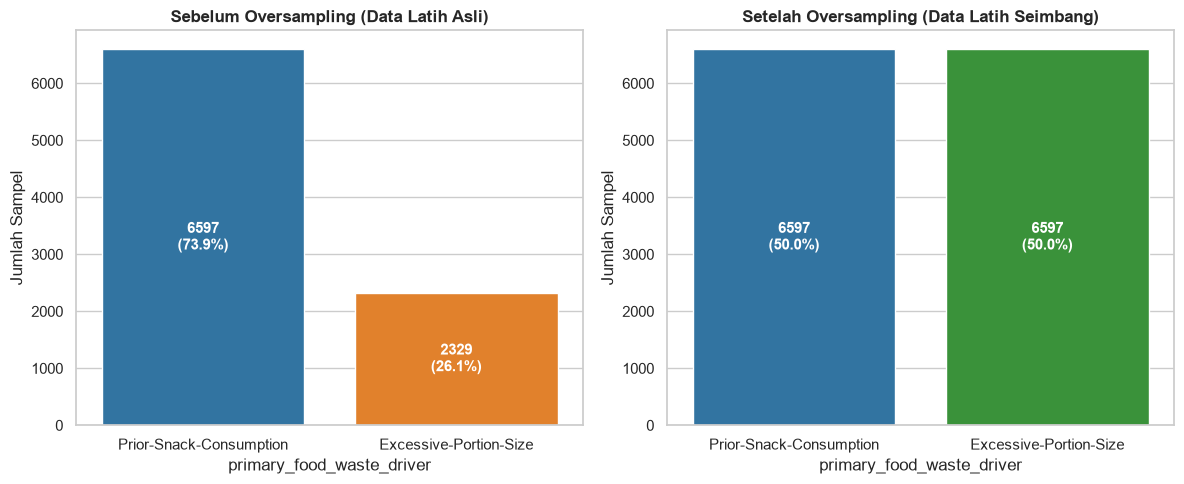

In [10]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.utils import resample

# 1. Load dataset dan filter 2 kelas biner
df = pd.read_csv('indonesia_mbg_nationwide_enriched_2026.csv')
features = ['beneficiary_category', 'protein_type', 'food_arrival_temperature_celsius', 'transit_time_minutes', 'plate_waste_percentage']
target = 'primary_food_waste_driver'

df_binary = df[df[target].isin(['Prior-Snack-Consumption', 'Excessive-Portion-Size'])].copy()
X = pd.get_dummies(df_binary[features], drop_first=True)
y = df_binary[target]

# 2. Split Data (80% Train, 20% Test) secara terstratifikasi
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
before_counts = y_train.value_counts()

# 3. Oversampling kelas minoritas khusus pada Data Latih
train_data = pd.concat([X_train, y_train], axis=1)
maj = train_data[train_data[target] == 'Prior-Snack-Consumption']
min_df = train_data[train_data[target] == 'Excessive-Portion-Size']

min_oversampled = resample(min_df, replace=True, n_samples=len(maj), random_state=42)
train_balanced = pd.concat([maj, min_oversampled])
after_counts = train_balanced[target].value_counts()

# 4. Visualisasi Perbandingan (Before vs After Oversampling)
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Plot 1: Sebelum Oversampling
sns.barplot(x=before_counts.index, y=before_counts.values, ax=axes[0], palette=['#1f77b4', '#ff7f0e'])
axes[0].set_title("Sebelum Oversampling (Data Latih Asli)", fontsize=12, fontweight='bold')
axes[0].set_ylabel("Jumlah Sampel")
for p in axes[0].patches:
    pct = (p.get_height() / len(y_train)) * 100
    axes[0].annotate(f"{int(p.get_height())}\n({pct:.1f}%)",
                     (p.get_x() + p.get_width() / 2., p.get_height() / 2),
                     ha='center', va='center', color='white', fontweight='bold', fontsize=11)

# Plot 2: Setelah Oversampling
sns.barplot(x=after_counts.index, y=after_counts.values, ax=axes[1], palette=['#1f77b4', '#2ca02c'])
axes[1].set_title("Setelah Oversampling (Data Latih Seimbang)", fontsize=12, fontweight='bold')
axes[1].set_ylabel("Jumlah Sampel")
for p in axes[1].patches:
    pct = (p.get_height() / len(train_balanced)) * 100
    axes[1].annotate(f"{int(p.get_height())}\n({pct:.1f}%)",
                     (p.get_x() + p.get_width() / 2., p.get_height() / 2),
                     ha='center', va='center', color='white', fontweight='bold', fontsize=11)

plt.tight_layout()
plt.show()

In [11]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.utils import resample
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report

# 1. Load dataset & filtering biner (2 kelas rekomendasi dosen)
df_raw = pd.read_csv('indonesia_mbg_nationwide_enriched_2026.csv')

features = [
    'beneficiary_category',
    'protein_type',
    'food_arrival_temperature_celsius',
    'transit_time_minutes',
    'plate_waste_percentage'
]
target = 'primary_food_waste_driver'

target_classes = ['Prior-Snack-Consumption', 'Excessive-Portion-Size']
df_binary = df_raw[df_raw[target].isin(target_classes)][features + [target]].copy()

# 2. Preprocessing (One-Hot Encoding)
X = pd.get_dummies(df_binary[features], drop_first=True)
y = df_binary[target]

# 3. Stratified Train-Test Split (80:20)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

# 4. Oversampling Data Latih (50% : 50%)
train_data = pd.concat([X_train, y_train], axis=1)
maj = train_data[train_data[target] == 'Prior-Snack-Consumption']
min_df = train_data[train_data[target] == 'Excessive-Portion-Size']

min_oversampled = resample(min_df, replace=True, n_samples=len(maj), random_state=42)
train_balanced = pd.concat([maj, min_oversampled])

X_train_res = train_balanced.drop(columns=[target])
y_train_res = train_balanced[target]

# 5. Pelatihan Model Random Forest
model = RandomForestClassifier(n_estimators=100, random_state=42)
model.fit(X_train_res, y_train_res)

print("Dataset & Model Random Forest berhasil dimuat dan dilatih!")
print(f"- Data Latih Seimbang : {X_train_res.shape[0]} sampel")
print(f"- Data Uji Murni      : {X_test.shape[0]} sampel")

Dataset & Model Random Forest berhasil dimuat dan dilatih!
- Data Latih Seimbang : 13194 sampel
- Data Uji Murni      : 2232 sampel
